# Epidemic Curve with Time-Varying Rt

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

Pairs the epidemic curve (daily cases by onset date, stacked by case status) with an estimate of the time-varying reproduction number Rt and its credible interval, on a shared time axis. The curve shows how many people are ill; Rt shows whether transmission is growing (above 1) or shrinking (below 1), which the curve alone reveals only after a delay.

## When to use

- Track an outbreak and judge whether control measures are working
- Brief decision-makers on whether incidence will rise or fall next
- Compare transmission before and after an intervention date

## Avoid when

- Case counts are tiny or reporting is very irregular (Rt estimates become noise; widen the window)
- Testing or case definitions changed a lot over the period (Rt partly tracks testing, not transmission)
- You don't have a credible serial-interval estimate for the pathogen

## Alternatives

- Epidemic curve alone with a 7-day average
- Growth rate or doubling time over time
- Nowcast with reporting-delay correction

## Design tips

- Plot cases by symptom-onset date, not report date, when you have it; recent days will be incomplete
- Always show Rt's interval, and draw the Rt = 1 threshold the reader judges against
- Share the x-axis with the epidemic curve, but keep them as separate panels (never a dual axis)
- Rt here uses the Cori et al. method with a 7-day window and a gamma serial interval (mean 4.7, SD 2.9 days); the estimate for each day uses that day and the six before it
- The grey line is the true Rt used in the simulation, shown only to check the estimate

## Example

A simulated outbreak over 110 days using a renewal process: the true reproduction number is 1.6 until physical-distancing measures on day 40, then falls to about 0.75. Around 70% of cases are laboratory confirmed and the rest probable.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from vizlib.health import epicurve, discretised_serial_interval, estimate_rt

### Data

In [2]:
rng = np.random.default_rng(2013)
days, intervention = 110, 40
dates = pd.date_range("2025-02-01", periods=days, freq="D")
serial_interval = discretised_serial_interval(mean=4.7, sd=2.9, max_days=20)
# True R: 1.6 until the measures, then ~0.75, with a one-week transition.
step = np.where(np.arange(days) < intervention, 1.6, 0.75)
true_r = np.convolve(np.r_[np.full(6, step[0]), step], np.ones(7) / 7, mode="valid")
cases = np.zeros(days, dtype=int)
cases[:5] = [3, 2, 4, 3, 5]
for t in range(5, days):                      # renewal process: new cases ~ Poisson(R * infectiousness)
    pressure = np.dot(cases[max(0, t - 20):t][::-1], serial_interval[:min(t, 20)])
    cases[t] = rng.poisson(true_r[t] * pressure)
onset = np.repeat(dates, cases)
confirmed = rng.random(onset.size) < 0.7
curve = pd.DataFrame({
    "confirmed": epicurve(onset[confirmed], start=dates[0], end=dates[-1]),
    "probable": epicurve(onset[~confirmed], start=dates[0], end=dates[-1]),
})
rt = estimate_rt(curve.sum(axis=1), serial_interval, window=7).loc[dates[10]:]
curve.assign(total=curve.sum(axis=1)).describe().round(0)

,confirmed,probable,total
count,110.0,110.0,110.0
mean,36.0,15.0,51.0
std,39.0,17.0,55.0
min,0.0,0.0,2.0
25%,7.0,3.0,10.0
50%,18.0,8.0,26.0
75%,48.0,24.0,74.0
max,157.0,68.0,214.0


### Plot

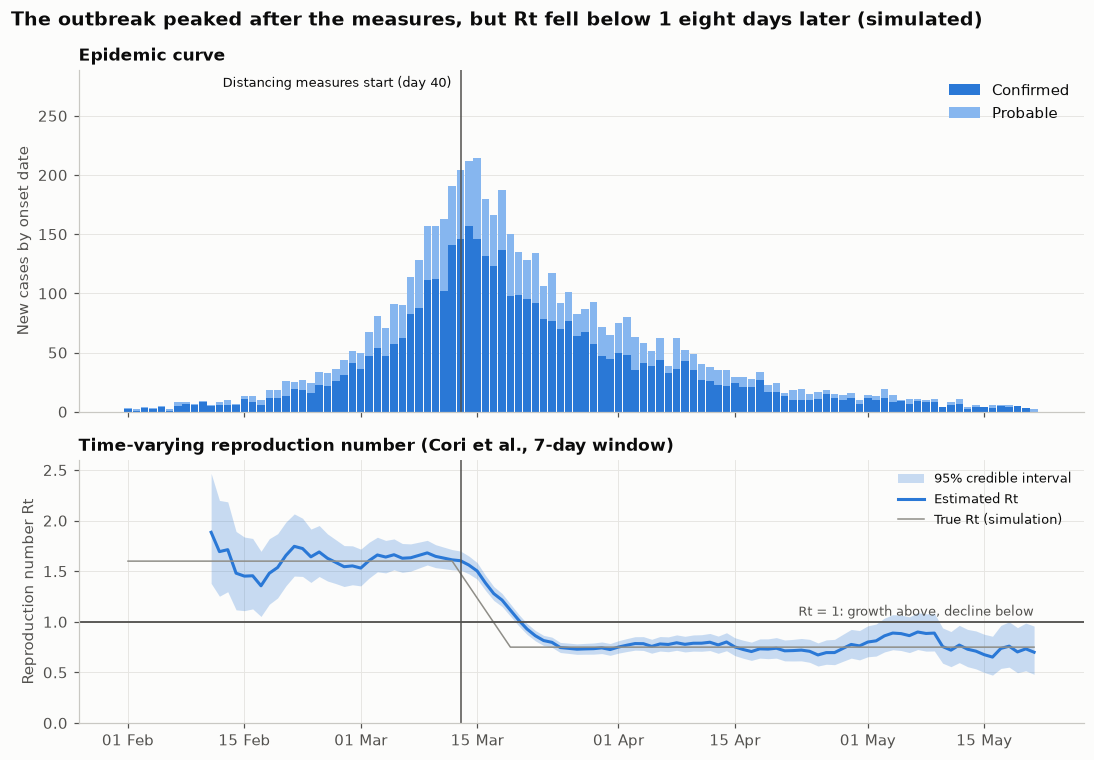

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
a1.bar(curve.index, curve["confirmed"], width=0.9, color=PALETTE[0], label="Confirmed")
a1.bar(curve.index, curve["probable"], bottom=curve["confirmed"], width=0.9, color="#86b6ef", label="Probable")
a1.set_ylabel("New cases by onset date")
a1.set_ylim(0, curve.sum(axis=1).max() * 1.35)
a1.set_title("Epidemic curve", fontsize=11)
a1.legend(loc="upper right")
a1.grid(axis="x", visible=False)
a2.fill_between(rt.index, rt["lower"], rt["upper"], color=PALETTE[0], alpha=0.25, linewidth=0,
                label="95% credible interval")
a2.plot(rt.index, rt["rt"], color=PALETTE[0], linewidth=2, label="Estimated Rt")
a2.plot(dates, true_r, color="#8f8e88", linewidth=1, label="True Rt (simulation)")
a2.axhline(1, color="#52514e", linewidth=1.2)
a2.text(dates[-1], 1.03, "Rt = 1: growth above, decline below", ha="right", va="bottom", fontsize=8.5,
        color="#52514e")
a2.set_ylim(0, 2.6)
a2.set_ylabel("Reproduction number Rt")
a2.set_title("Time-varying reproduction number (Cori et al., 7-day window)", fontsize=11)
a2.legend(loc="upper right", fontsize=8.5)
for ax in (a1, a2):
    ax.axvline(dates[intervention], color="#52514e", linewidth=1)
a1.annotate("Distancing measures start (day 40)", (dates[intervention], a1.get_ylim()[1]), xytext=(-6, -4),
            textcoords="offset points", ha="right", va="top", fontsize=8.5)
a2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
fig.suptitle("The outbreak peaked after the measures, but Rt fell below 1 eight days later (simulated)",
             x=0.01, ha="left", fontweight="bold", fontsize=12.5)
fig.tight_layout()
plt.show()

## How to read it

Cases keep rising for a few days after the measures and peak on day 42, because infections already under way keep producing cases; the decline that follows is slow. Rt drops through 1 about eight days after the measures and stays below it, signalling a sustained decline even while daily counts were still near their peak. The grey line shows the estimate tracking the true simulated Rt.

## Reference

This method comes from the research literature:

- Cori, A., Ferguson, N. M., Fraser, C. & Cauchemez, S. (2013). A new framework and software to estimate time-varying reproduction numbers during epidemics. American Journal of Epidemiology 178(9), 1505–1512. <https://doi.org/10.1093/aje/kwt133>

---
Standalone script: [`epidemic_curve_rt.py`](epidemic_curve_rt.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)